# Comparing Nine Sequence Models for Electricity Forecasting

Hourly household power consumption has daily patterns, irregular spikes, and missing
measurements. We compare nine models on the same task: predict the next 24 hours
from the previous 168 hourly observations.

The comparison uses only past demand. Calendar variables, weather, and other electrical
measurements are excluded so the input information remains the same across models.
We measure forecast error and parameter count.

This notebook contains the dataset, complete model definitions, training code, and
executed results. Its explanations and figures also form a technical article. A separate
`Medium_article.md` and publication figures are included in the accompanying package.
Run cells in order to reproduce the experiment; all nine models are enabled by default.

## Data source and preprocessing

| Item | Source / definition |
|---|---|
| Dataset | [UCI Individual Household Electric Power Consumption, ID 235](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption) |
| Direct download | [Official UCI ZIP](https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip) |
| Original file | `household_power_consumption.txt`, semicolon-separated |
| Creators | Georges Hebrail and Alice Berard |
| Citation | Hebrail, G. & Berard, A. (2006). *Individual Household Electric Power Consumption*. UCI Machine Learning Repository. [DOI: 10.24432/C58K54](https://doi.org/10.24432/C58K54) |
| License | [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) |
| Population | One home in Sceaux, France; this is **not national electricity demand** |
| Raw resolution | One minute, December 2006–November 2010; 2,075,259 rows |
| Forecast variable | `Global_active_power`, minute-average active power in **kilowatts** |
| Our transformation | Mean within each clock hour; forward-fill hours with no valid readings |

Hourly **mean power remains kW**; it is not the sum of 60 power measurements.
Hour labels are the start of `[hour, hour + 1 hour)` and become available only after
that interval ends. The original wall-clock timestamps are kept timezone-naive.
The first and last clock hours are partial and are retained explicitly.

Missing readings are parsed as NaN. Hourly means use available minute readings.
Only an hour with **zero** valid readings is forward-filled from the past; no
backfilling or interpolation from the future is used. The observation counts and
an imputation flag are retained. Long gaps still make this a simplified tutorial
dataset; we report a second RMSE excluding imputed target hours.

`SOURCE_MODE = "bundled"` loads the supplied CSV, or an identical compressed snapshot
embedded below when this notebook is downloaded alone. Change it to `"uci"` to
rebuild directly from the official raw ZIP. Both paths verify recorded SHA-256 hashes.

## Running on Mac, CPU, GPU, or TPU

Leave `REQUESTED_DEVICE = "auto"` for normal use, or choose a backend explicitly.
All model tensors use float32; the float64 metric calculations stay in NumPy on CPU.

| Environment | Device option | Setup |
|---|---|---|
| Intel Mac / Linux / Windows CPU | `cpu` or `auto` | Standard compatible PyTorch build |
| Apple silicon Mac | `mps` or `auto` | macOS/PyTorch with MPS support; unsupported MPS operators may fall back to CPU |
| NVIDIA GPU | `cuda` or `auto` | PyTorch CUDA build and working driver |
| AMD GPU | `cuda` or `auto` | Supported ROCm build; PyTorch uses the CUDA API name for ROCm |
| Intel GPU | `xpu` or `auto` | PyTorch XPU build and working runtime |
| Cloud TPU, native backend | `tpu` (or detected by `auto`) | Install `torch_tpu` on a TPU host and restart the kernel |
| Existing TPU/XLA environment | `xla` | Matching `torch` / `torch_xla[tpu]` versions; explicit lazy optimizer steps are included |

This notebook uses one selected device. Distributed multi-GPU or TPU-pod training
is not configured. GPU and TPU availability depends on the installed backend and
hardware. The preflight cell checks a forward pass, backward pass, and optimizer
step for every model before the full run. In `auto` mode, an unsupported accelerator
operator triggers a clearly reported CPU fallback for the entire comparison.

The displayed benchmark was executed on CPU. The portability update was checked
with a separate CPU smoke test; no Mac GPU, CUDA, ROCm, XPU, or TPU hardware was
available for verification here. If memory is limited, lower `BATCH_SIZE`, for
example to 64. Restart the kernel after changing packages or MPS fallback settings.

Setup references: [PyTorch installer](https://pytorch.org/get-started/locally/),
[MPS](https://docs.pytorch.org/docs/stable/notes/mps.html),
[ROCm](https://docs.pytorch.org/docs/stable/notes/hip.html),
[Intel XPU](https://docs.pytorch.org/docs/stable/xpu.html),
[native TorchTPU](https://docs.cloud.google.com/tpu/docs/pytorch-on-tpu).
TorchTPU is the current TPU path; XLA is retained for existing environments.

In [1]:
# Run only the setup appropriate for your environment, then restart the kernel.
# Mac / CPU / ordinary PyTorch environment:
# %pip install numpy pandas matplotlib torch jupyterlab
# NVIDIA / AMD / Intel GPUs: install the hardware build from https://pytorch.org/get-started/locally/
# Native Cloud TPU (separate Linux TPU environment):
# %pip install torch_tpu --extra-index-url https://download.pytorch.org/whl/cpu
# Legacy TPU/XLA environment only (do not combine with native TorchTPU):
# %pip install "torch==2.8.0" "torch_xla[tpu]==2.8.0"
# Older Intel Mac CPU environment, if current torch wheels are unavailable:
# %pip install "torch==2.2.2" "numpy<2" "pandas<3" matplotlib jupyterlab

In [2]:
import base64
import copy
import gzip
import hashlib
import io
import json
import math
import os
import platform
import subprocess
import random
import time
import urllib.request
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")  # Set before importing torch.
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from IPython.display import display

SOURCE_MODE = "bundled"  # "uci" rebuilds the data from the official raw archive.
LOOKBACK = 168
HORIZON = 24
SEED = 42
BATCH_SIZE = 256
MAX_EPOCHS = 15
PATIENCE = 3
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
REPORT_TIMING = False  # Set True to measure/report fit time on your own hardware.
MODEL_NAMES = ["Linear", "MLP", "GRU", "LSTM", "CNN1D", "TCN",
               "Patch Transformer", "N-BEATS-style", "Transformer"]
REQUESTED_DEVICE = "auto"  # auto / cpu / cuda / mps / xpu / tpu / xla; cuda:1 also works.
torch_xla = xm = None

def select_device(requested="auto"):
    global torch_xla, xm
    requested = requested.lower()
    if requested == "auto":
        if torch.cuda.is_available():
            return torch.device("cuda")  # NVIDIA CUDA or AMD ROCm PyTorch build.
        if hasattr(torch, "xpu") and torch.xpu.is_available():
            return torch.device("xpu")
        if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
            return torch.device("mps")
        if hasattr(torch, "accelerator") and torch.accelerator.is_available():
            accelerator = torch.accelerator.current_accelerator()
            if accelerator is not None and accelerator.type == "tpu":
                return torch.device("tpu")
        return torch.device("cpu")
    if requested in ("tpu", "xla"):
        if requested == "tpu":
            try:
                import torch_tpu  # Optional native TPU backend; installed only on a TPU host.
            except ImportError as error:
                raise RuntimeError("Install torch_tpu on a Cloud TPU host, restart the kernel, "
                                   "and select REQUESTED_DEVICE='tpu'.") from error
            return torch.device("tpu")
        os.environ.setdefault("PJRT_DEVICE", "TPU")
        try:
            import torch_xla
            import torch_xla.core.xla_model as xm
        except ImportError as error:
            raise RuntimeError("For legacy TPU/XLA, install matching torch and torch_xla[tpu] "
                               "versions in a separate TPU environment and restart.") from error
        return torch_xla.device() if hasattr(torch_xla, "device") else xm.xla_device()
    kind = requested.split(":")[0]
    available = {"cpu": True, "cuda": torch.cuda.is_available(),
                 "mps": hasattr(torch.backends, "mps") and torch.backends.mps.is_available(),
                 "xpu": hasattr(torch, "xpu") and torch.xpu.is_available()}
    if kind not in available or not available[kind]:
        raise RuntimeError(f"Device {requested!r} is unavailable in this PyTorch installation. "
                           "Use 'auto'/'cpu' or install the build for your hardware.")
    return torch.device(requested)

DEVICE = select_device(REQUESTED_DEVICE)

def synchronize_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)
    elif DEVICE.type == "mps":
        torch.mps.synchronize()
    elif DEVICE.type == "xpu":
        torch.xpu.synchronize(DEVICE)
    elif DEVICE.type == "tpu":
        if hasattr(torch, "accelerator") and hasattr(torch.accelerator, "synchronize"):
            torch.accelerator.synchronize()
        else:
            torch.tpu.synchronize()
    elif DEVICE.type == "xla":
        if hasattr(torch_xla, "sync"):
            torch_xla.sync(wait=True)
        else:
            xm.mark_step()
            xm.wait_device_ops()

def optimizer_step(optimizer):
    optimizer.step()
    if DEVICE.type == "xla":
        # XLA is lazy; materialize each optimizer update explicitly.
        if hasattr(torch_xla, "sync"):
            torch_xla.sync()
        else:
            xm.mark_step()

def clear_device_cache():
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    elif DEVICE.type == "mps":
        torch.mps.empty_cache()
    elif DEVICE.type == "xpu" and hasattr(torch.xpu, "empty_cache"):
        torch.xpu.empty_cache()
torch.set_num_threads(min(4, os.cpu_count() or 1))
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
(OUTPUT_DIR / "weights").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    if DEVICE.type == "mps":
        torch.mps.manual_seed(seed)
    elif DEVICE.type == "xpu":
        torch.xpu.manual_seed_all(seed)
    elif DEVICE.type == "tpu":
        torch.tpu.manual_seed_all(seed)
    elif DEVICE.type == "xla":
        xm.set_rng_state(seed, str(DEVICE))

def hardware_summary():
    system = platform.system()
    processor = platform.processor() or platform.machine()
    if system == "Darwin":
        try:
            probe = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"],
                capture_output=True, text=True, check=False, timeout=5)
            processor = probe.stdout.strip() or processor
        except (OSError, subprocess.SubprocessError):
            pass
    accelerator = "CPU"
    if DEVICE.type == "cuda":
        accelerator = torch.cuda.get_device_name(DEVICE)
    elif DEVICE.type == "mps":
        accelerator = f"Apple Metal / {processor}"
    elif DEVICE.type == "xpu":
        accelerator = torch.xpu.get_device_name(DEVICE)
    elif DEVICE.type in ("tpu", "xla"):
        accelerator = f"TPU backend ({DEVICE.type})"
    return {"operating_system": "macOS" if system == "Darwin" else system,
            "os_version": platform.mac_ver()[0] if system == "Darwin" else platform.release(),
            "architecture": platform.machine(), "processor": processor,
            "device": str(DEVICE), "accelerator": accelerator,
            "torch_version": torch.__version__, "cpu_threads": torch.get_num_threads(),
            "dtype": "float32", "batch_size": BATCH_SIZE,
            "mps_cpu_fallback_enabled": DEVICE.type == "mps" and
                os.environ.get("PYTORCH_ENABLE_MPS_FALLBACK") == "1"}

def write_local_timing_report(results):
    if not REPORT_TIMING:
        return
    local = results.loc[results["kind"] == "Learned",
        ["model", "training_seconds", "epochs_run", "best_epoch"]].copy()
    local = local.rename(columns={"training_seconds": "fit_wall_seconds"})
    hardware = hardware_summary()
    for key in ("device", "operating_system", "accelerator", "batch_size"):
        local[key] = hardware[key]
    local.to_csv(OUTPUT_DIR / "local_timing.csv", index=False)
    details = {"recorded_utc": datetime.now(timezone.utc).isoformat(),
        "hardware": hardware,
        "timing_scope": "training + validation + checkpoint and history writes",
        "excluded": "model initialization, best-checkpoint restore, final test prediction",
        "first_use_compilation": "included when required by the selected backend",
        "synchronization": "selected accelerator synchronized before and after the fit loop",
        "interpretation": "local diagnostics; no comparison across different machines"}
    (OUTPUT_DIR / "local_timing_metadata.json").write_text(json.dumps(details, indent=2))
    print("Local fit times on this machine (training + validation + checkpoint writes):")
    display(local.round({"fit_wall_seconds": 2}))
    print(json.dumps(hardware, indent=2))

seed_everything()
environment = {"python": platform.python_version(), "numpy": np.__version__,
               "pandas": pd.__version__, "torch": torch.__version__,
               "matplotlib": matplotlib.__version__, "device": str(DEVICE),
               "cpu_threads": torch.get_num_threads(), "requested_device": REQUESTED_DEVICE,
               "hip_version": getattr(torch.version, "hip", None)}
print(json.dumps(environment, indent=2))

{
  "python": "3.12.14",
  "numpy": "2.3.5",
  "pandas": "2.2.3",
  "torch": "2.5.1+cpu",
  "matplotlib": "3.10.8",
  "device": "cpu",
  "cpu_threads": 4,
  "requested_device": "auto",
  "hip_version": null
}


The next collapsed cell is only the compressed CSV snapshot, included so this is a
standalone notebook. All preprocessing and modeling code is in the readable cells after it.

In [3]:
EMBEDDED_HOURLY_CSV_GZIP_BASE64 = '...'

In [4]:
DATASET_PAGE = "https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption"
RAW_URL = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"
RAW_ZIP_SHA256 = "9f84b46ade8a2d8e1286ec4b2b6c2987a45a755c59f263be3b3b3d10dfbda3ff"
HOURLY_CSV_SHA256 = "afbfc86aad2fbc2b0466fab43ea7bf58d089b2d287e229dbb883eafaf8e8c758"
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
HOURLY_CSV = DATA_DIR / "electricity_hourly.csv"
CACHE_DIR = Path(".cache")
CACHE_DIR.mkdir(exist_ok=True)

def sha256_bytes(content):
    return hashlib.sha256(content).hexdigest()

def rebuild_hourly_from_uci():
    archive = CACHE_DIR / "household_power_consumption.zip"
    if not archive.exists():
        print("Downloading the official UCI archive (~20 MB):", RAW_URL)
        temporary = archive.with_suffix(".zip.part")
        urllib.request.urlretrieve(RAW_URL, temporary)
        temporary.replace(archive)
    raw_zip = archive.read_bytes()
    if sha256_bytes(raw_zip) != RAW_ZIP_SHA256:
        raise ValueError("UCI archive checksum changed. Inspect the source before proceeding.")
    with zipfile.ZipFile(io.BytesIO(raw_zip)) as z:
        with z.open("household_power_consumption.txt") as f:
            minute = pd.read_csv(f, sep=";", na_values=["?"],
                                 usecols=["Date", "Time", "Global_active_power"])
    timestamps = pd.to_datetime(minute["Date"] + " " + minute["Time"],
                                format="%d/%m/%Y %H:%M:%S")
    raw = pd.Series(minute["Global_active_power"].to_numpy(), index=timestamps,
                    name="demand_kw")
    assert raw.index.is_monotonic_increasing and raw.index.is_unique
    hourly = raw.resample("h").agg(["mean", "count", "size"])
    hourly = hourly.rename(columns={"mean": "demand_kw_observed",
                                      "count": "valid_minutes", "size": "recorded_minutes"})
    hourly["demand_kw"] = hourly["demand_kw_observed"].ffill()
    hourly["was_imputed"] = hourly["demand_kw_observed"].isna()
    # Drop only leading hours with no previous observation. This archive has none.
    hourly = hourly.loc[hourly["demand_kw"].notna(),
                          ["demand_kw", "demand_kw_observed", "valid_minutes",
                           "recorded_minutes", "was_imputed"]]
    hourly.index.name = "timestamp"
    csv_content = hourly.to_csv(float_format="%.10g").encode("utf-8")
    if sha256_bytes(csv_content) != HOURLY_CSV_SHA256:
        raise ValueError("The rebuilt hourly CSV differs from the supplied snapshot.")
    HOURLY_CSV.write_bytes(csv_content)
    raw_audit = {"minute_rows": len(raw), "missing_minute_readings": int(raw.isna().sum()),
                 "first_minute": str(raw.index[0]), "last_minute": str(raw.index[-1])}
    print("Raw data audit:", raw_audit)
    return csv_content

if SOURCE_MODE == "uci":
    csv_content = rebuild_hourly_from_uci()
elif SOURCE_MODE == "bundled":
    csv_content = (HOURLY_CSV.read_bytes() if HOURLY_CSV.exists() else
                   gzip.decompress(base64.b64decode(EMBEDDED_HOURLY_CSV_GZIP_BASE64)))
    if sha256_bytes(csv_content) != HOURLY_CSV_SHA256:
        raise ValueError("The hourly CSV was modified. Use an unchanged copy or rebuild it.")
    HOURLY_CSV.write_bytes(csv_content)
else:
    raise ValueError("SOURCE_MODE must be 'bundled' or 'uci'.")

hourly = pd.read_csv(io.BytesIO(csv_content), parse_dates=["timestamp"]).set_index("timestamp")
assert len(hourly) == 34589
assert hourly.index.is_unique and hourly.index.is_monotonic_increasing
assert (hourly.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all()
assert hourly["demand_kw"].notna().all()
assert (hourly["was_imputed"] == hourly["demand_kw_observed"].isna()).all()
assert np.allclose(hourly["demand_kw"], hourly["demand_kw_observed"].ffill())

audit = {"dataset": DATASET_PAGE, "raw_download": RAW_URL,
         "doi": "10.24432/C58K54", "license": "CC BY 4.0",
         "raw_zip_sha256": RAW_ZIP_SHA256, "hourly_csv_sha256": HOURLY_CSV_SHA256,
         "raw_rows": 2075259, "missing_minute_readings": 25979,
         "hourly_rows": len(hourly), "first_hour": str(hourly.index[0]),
         "last_hour": str(hourly.index[-1]),
         "forward_filled_hours": int(hourly["was_imputed"].sum()),
         "partial_edge_hours": int((hourly["recorded_minutes"] < 60).sum()),
         "units": "kW", "timestamp_convention": "naive local clock; interval start",
         "preprocessing": "hourly mean of available minute readings; forward fill empty hours"}
(DATA_DIR / "source_metadata.json").write_text(json.dumps(audit, indent=2))
display(pd.Series(audit).rename("value").to_frame())
display(hourly.head())

,value
dataset,https://archive.ics.uci.edu/dataset/235/indivi...
raw_download,https://archive.ics.uci.edu/static/public/235/...
doi,10.24432/C58K54
license,CC BY 4.0
raw_zip_sha256,9f84b46ade8a2d8e1286ec4b2b6c2987a45a755c59f263...
hourly_csv_sha256,afbfc86aad2fbc2b0466fab43ea7bf58d089b2d287e229...
raw_rows,2075259
missing_minute_readings,25979
hourly_rows,34589
first_hour,2006-12-16 17:00:00


,demand_kw,demand_kw_observed,valid_minutes,recorded_minutes,was_imputed
timestamp,,,,,
2006-12-16 17:00:00,4.222889,4.222889,36,36,False
2006-12-16 18:00:00,3.632200,3.632200,60,60,False
2006-12-16 19:00:00,3.400233,3.400233,60,60,False
2006-12-16 20:00:00,3.268567,3.268567,60,60,False
2006-12-16 21:00:00,3.056467,3.056467,60,60,False


## Forecasting task and evaluation

The time axis is split at `floor(0.70 * N)` and `floor(0.85 * N)`.
A forecast origin `t` uses `demand[t-168:t]` and predicts `demand[t:t+24]`.
All 24 targets must belong to the same partition. Validation and test inputs
may use earlier observations from the preceding partition, which are available
at forecast time. Scaling statistics are fitted on the training period only.

This gives **24,021 training, 5,165 validation, and 5,166 test origins**.
Origins advance by one hour, so their 24-hour targets overlap. Their errors
are correlated; they are not independent daily forecast trials.

Training-only scaler: mean=1.084858 kW; std=0.926933 kW


,origins,first_origin,last_origin,last_target
partition,,,,
Train,24021,2006-12-23 17:00:00,2009-09-19 13:00:00,2009-09-20 12:00:00
Validation,5165,2009-09-20 13:00:00,2010-04-23 17:00:00,2010-04-24 16:00:00
Test,5166,2010-04-24 17:00:00,2010-11-25 22:00:00,2010-11-26 21:00:00


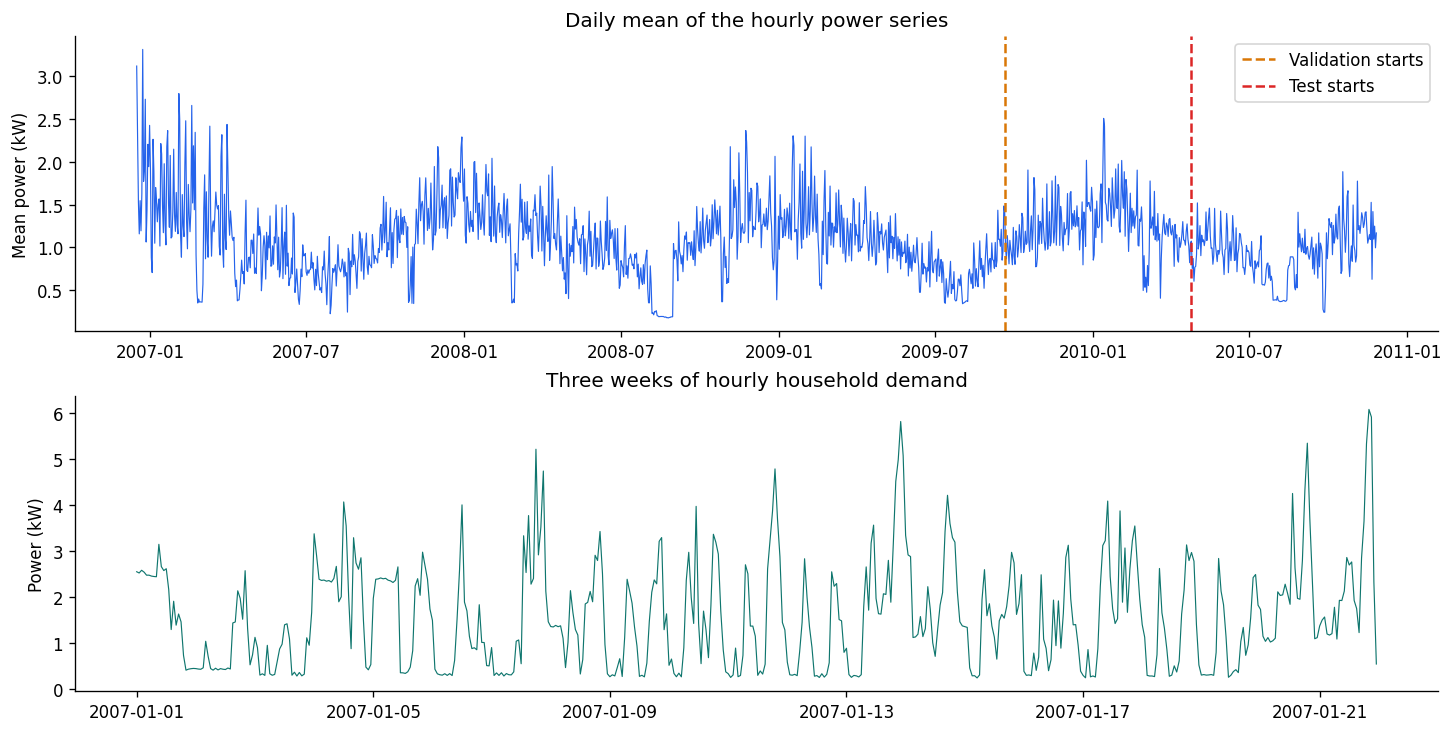

In [5]:
n = len(hourly)
train_end = int(0.70 * n)
val_end = int(0.85 * n)
origin_sets = {
    "Train": np.arange(LOOKBACK, train_end - HORIZON + 1),
    "Validation": np.arange(train_end, val_end - HORIZON + 1),
    "Test": np.arange(val_end, n - HORIZON + 1),
}
for name, origins in origin_sets.items():
    assert len(origins) and origins[0] >= LOOKBACK
    assert origins[-1] + HORIZON <= {"Train": train_end, "Validation": val_end, "Test": n}[name]
assert origin_sets["Train"][-1] + HORIZON <= origin_sets["Validation"][0]
assert origin_sets["Validation"][-1] + HORIZON <= origin_sets["Test"][0]

values = hourly["demand_kw"].to_numpy(dtype=np.float64)
observed = hourly["valid_minutes"].to_numpy() > 0
train_mean = values[:train_end].mean()
train_std = values[:train_end].std(ddof=0)
assert train_std > 0
z = ((values - train_mean) / train_std).astype(np.float32)

split_table = pd.DataFrame([
    {"partition": name, "origins": len(origins),
     "first_origin": hourly.index[origins[0]],
     "last_origin": hourly.index[origins[-1]],
     "last_target": hourly.index[origins[-1] + HORIZON - 1]}
    for name, origins in origin_sets.items()
]).set_index("partition")
display(split_table)
print(f"Training-only scaler: mean={train_mean:.6f} kW; std={train_std:.6f} kW")

fig, axes = plt.subplots(2, 1, figsize=(12, 6), constrained_layout=True)
daily = hourly["demand_kw"].resample("D").mean()
axes[0].plot(daily.index, daily, lw=0.7, color="#2563eb")
axes[0].axvline(hourly.index[train_end], color="#d97706", ls="--", label="Validation starts")
axes[0].axvline(hourly.index[val_end], color="#dc2626", ls="--", label="Test starts")
axes[0].set(title="Daily mean of the hourly power series", ylabel="Mean power (kW)")
axes[0].legend(loc="upper right")
sample = hourly.loc["2007-01-01":"2007-01-21 23:00", "demand_kw"]
axes[1].plot(sample.index, sample, lw=0.7, color="#0f766e")
axes[1].set(title="Three weeks of hourly household demand", ylabel="Power (kW)")
fig.savefig(OUTPUT_DIR / "electricity_data.png", bbox_inches="tight")
plt.show()

In [6]:
class ForecastDataset(Dataset):
    def __init__(self, standardized_values, origins):
        self.values = torch.as_tensor(standardized_values, dtype=torch.float32)
        self.origins = np.asarray(origins)

    def __len__(self):
        return len(self.origins)

    def __getitem__(self, index):
        t = int(self.origins[index])
        return self.values[t-LOOKBACK:t, None], self.values[t:t+HORIZON]

datasets = {name: ForecastDataset(z, origins) for name, origins in origin_sets.items()}

def make_loader(name, shuffle=False):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(datasets[name], batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=0, generator=generator,
                      pin_memory=DEVICE.type == "cuda")

validation_loader = make_loader("Validation")
test_loader = make_loader("Test")
xb, yb = next(iter(make_loader("Train")))
print("X:", tuple(xb.shape), "y:", tuple(yb.shape))
assert xb.shape[1:] == (LOOKBACK, 1) and yb.shape[1:] == (HORIZON,)

test_origins = origin_sets["Test"]
y_test_kw = np.stack([values[t:t+HORIZON] for t in test_origins])
observed_test_mask = np.stack([observed[t:t+HORIZON] for t in test_origins])
print(f"Observed target cells: {observed_test_mask.mean():.2%}")

X: (256, 168, 1) y: (256, 24)
Observed target cells: 96.01%


## Baseline forecasts

The main RMSE averages squared errors over **every test origin and all 24 forecast
horizons**, then takes one square root, in kW. It includes forward-filled targets,
using the same processed series as training. `observed_rmse_kw` excludes
target hours with no valid minute readings. Partially observed hours are retained.
Baseline predictions and all neural models use exactly the same test-origin array.

In [7]:
def score_predictions(prediction_kw):
    assert prediction_kw.shape == y_test_kw.shape
    assert np.isfinite(prediction_kw).all()
    error = np.asarray(prediction_kw, dtype=np.float64) - y_test_kw
    return {"test_rmse_kw": float(np.sqrt(np.mean(error**2))),
            "observed_rmse_kw": float(np.sqrt(np.mean(error[observed_test_mask]**2))),
            "test_mae_kw": float(np.mean(np.abs(error)))}

baseline_predictions = {
    "Yesterday": np.stack([values[t-24:t] for t in test_origins]),
    "Last week": np.stack([values[t-168:t-144] for t in test_origins]),
    "Last observed value": np.stack([np.repeat(values[t-1], HORIZON) for t in test_origins]),
}
baseline_rows = [{"model": name, "kind": "Naive", **score_predictions(prediction),
                  "parameters": 0, "epochs_run": 0, "best_epoch": 0,
                  "validation_rmse_kw": np.nan, "training_seconds": 0.0}
                 for name, prediction in baseline_predictions.items()]
baselines = pd.DataFrame(baseline_rows).sort_values("test_rmse_kw")
display(baselines[["model", "test_rmse_kw", "observed_rmse_kw", "test_mae_kw"]].round(6))

article_baselines = {"Yesterday": 0.7496, "Last week": 0.8025, "Last observed value": 0.9179}
for row in baseline_rows:
    assert abs(row["test_rmse_kw"] - article_baselines[row["model"]]) < 0.00005
print("All three baseline scores agree with the article to four decimals.")

All three baseline scores agree with the article to four decimals.


,model,test_rmse_kw,observed_rmse_kw,test_mae_kw
0,Yesterday,0.749631,0.761792,0.497080
1,Last week,0.802534,0.806139,0.561395
2,Last observed value,0.917863,0.935385,0.657520


## Model definitions

Every model receives `[batch, 168, 1]` and returns `[batch, 24]`.
No calendar variables, weather, additional power channels, or engineered features are inputs.

| Model | Implementation in this notebook |
|---|---|
| Linear | Flatten 168 values; one linear map to 24 outputs |
| MLP | Dense 168 → 256 → 128 → 24, ReLU and dropout |
| CNN1D | Three convolutions (32/64/64 channels, kernel 5), global average pooling |
| TCN | Four causal convolutions, 64 channels, kernel 3, dilations 1/2/4/8; last-state head |
| GRU | One 64-unit gated recurrent layer; last-state head |
| LSTM | One 64-unit recurrent layer; last-state head |
| Transformer | 64-dimensional tokens, learned positions, two encoder blocks, four heads, feed-forward width 128; mean pooling |
| Patch Transformer | Nonoverlapping 12-hour patches (14 tokens); otherwise the same encoder dimensions |
| N-BEATS-style | Three generic residual blocks, each with three 256-unit dense layers and backcast/forecast heads |

The TCN uses a **31-hour receptive field**. It receives
the same tensor, but its final state cannot use the whole week. This limits what
its ranking says about TCNs. To test full-week coverage in a separate run, use
`dilations=(1, 2, 4, 8, 16, 32, 64)`; that changes both capacity and compute.

The CNN's global pooling also discards exact positions. The N-BEATS-style model is
a generic residual dense implementation, not a full reproduction of every feature
of the original N-BEATS paper. These explicit model definitions govern the results below. Parameter counts are calculated.

In [8]:
class LinearForecast(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(LOOKBACK, HORIZON))

    def forward(self, x):
        return self.net(x)


class MLPForecast(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(LOOKBACK, 256), nn.ReLU(),
                                  nn.Dropout(0.1), nn.Linear(256, 128), nn.ReLU(),
                                  nn.Dropout(0.1), nn.Linear(128, HORIZON))

    def forward(self, x):
        return self.net(x)


class CNNForecast(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, 32, 5, padding=2), nn.ReLU(),
            nn.Conv1d(32, 64, 5, padding=2), nn.ReLU(),
            nn.Conv1d(64, 64, 5, padding=2), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1))
        self.head = nn.Linear(64, HORIZON)

    def forward(self, x):
        return self.head(self.features(x.transpose(1, 2)).squeeze(-1))


class CausalConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dilation):
        super().__init__()
        self.left_padding = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(in_channels, out_channels, kernel_size, dilation=dilation)

    def forward(self, x):
        return self.conv(F.pad(x, (self.left_padding, 0)))


class TCNForecast(nn.Module):
    def __init__(self, dilations=(1, 2, 4, 8)):
        super().__init__()
        layers, channels = [], 1
        for dilation in dilations:
            layers += [CausalConv1d(channels, 64, 3, dilation), nn.ReLU(), nn.Dropout(0.1)]
            channels = 64
        self.net = nn.Sequential(*layers)
        self.head = nn.Linear(64, HORIZON)
        self.receptive_field = 1 + 2 * sum(dilations)

    def forward(self, x):
        return self.head(self.net(x.transpose(1, 2))[:, :, -1])


class RecurrentForecast(nn.Module):
    def __init__(self, kind):
        super().__init__()
        recurrent_class = {"GRU": nn.GRU, "LSTM": nn.LSTM}[kind]
        self.recurrent = recurrent_class(input_size=1, hidden_size=64, batch_first=True)
        self.head = nn.Linear(64, HORIZON)

    def forward(self, x):
        sequence, _ = self.recurrent(x)
        return self.head(sequence[:, -1])


class TransformerForecast(nn.Module):
    def __init__(self, patch_size=1):
        super().__init__()
        assert LOOKBACK % patch_size == 0
        self.patch_size = patch_size
        token_count = LOOKBACK // patch_size
        self.project = nn.Linear(patch_size, 64)
        self.positions = nn.Parameter(torch.randn(1, token_count, 64) * 0.02)
        layer = nn.TransformerEncoderLayer(d_model=64, nhead=4, dim_feedforward=128,
                                           dropout=0.1, activation="gelu", batch_first=True,
                                           norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=2, norm=nn.LayerNorm(64),
                                             enable_nested_tensor=False)
        self.head = nn.Linear(64, HORIZON)

    def forward(self, x):
        tokens = x.squeeze(-1).reshape(x.shape[0], LOOKBACK // self.patch_size, self.patch_size)
        encoded = self.encoder(self.project(tokens) + self.positions)
        # Attention sees only the observed history, so no future-target mask is needed.
        return self.head(encoded.mean(dim=1))


class NBeatsBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Sequential(nn.Linear(LOOKBACK, 256), nn.ReLU(),
                                    nn.Linear(256, 256), nn.ReLU(),
                                    nn.Linear(256, 256), nn.ReLU())
        self.backcast = nn.Linear(256, LOOKBACK)
        self.forecast = nn.Linear(256, HORIZON)

    def forward(self, residual):
        hidden = self.hidden(residual)
        return self.backcast(hidden), self.forecast(hidden)


class NBeatsForecast(nn.Module):
    def __init__(self):
        super().__init__()
        self.blocks = nn.ModuleList([NBeatsBlock() for _ in range(3)])

    def forward(self, x):
        residual = x.squeeze(-1)
        forecast = x.new_zeros((x.shape[0], HORIZON))
        for block in self.blocks:
            backcast, increment = block(residual)
            residual = residual - backcast
            forecast = forecast + increment
        return forecast


MODEL_FACTORIES = {
    "Linear": LinearForecast,
    "MLP": MLPForecast,
    "CNN1D": CNNForecast,
    "TCN": TCNForecast,
    "GRU": lambda: RecurrentForecast("GRU"),
    "LSTM": lambda: RecurrentForecast("LSTM"),
    "Transformer": TransformerForecast,
    "Patch Transformer": lambda: TransformerForecast(patch_size=12),
    "N-BEATS-style": NBeatsForecast,
}

def parameter_count(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

architecture_rows = []
for name in MODEL_NAMES:
    seed_everything()
    model = MODEL_FACTORIES[name]().eval()
    with torch.no_grad():
        output = model(xb[:2])
    assert output.shape == (2, HORIZON) and torch.isfinite(output).all()
    architecture_rows.append({"model": name, "parameters": parameter_count(model)})
display(pd.DataFrame(architecture_rows).set_index("model"))
print("All nine models satisfy the input/output contract.")
del model

All nine models satisfy the input/output contract.


,parameters
model,
Linear,4056
MLP,79256
GRU,14424
LSTM,18712
CNN1D,32600
TCN,38872
Patch Transformer,70360
N-BEATS-style,672576
Transformer,79512


## Training protocol

One seed, AdamW, learning rate 0.001, batch size 256, MSE on the standardized target,
gradient clipping at 1.0, at most 15 epochs, and early stopping after three epochs
without validation improvement. Each model restores its lowest-validation-loss
checkpoint before test evaluation. Forward-filled targets are included in training
to match the processed-series experiment. Architecture capacity is not matched.

The data order is independently reset to the same seed for each model. Hyperparameters
are fixed before evaluating the test set. The test set does not choose the epoch.
Optional local timing is controlled by `REPORT_TIMING = False`. Set it to `True`
to save `outputs/local_timing.csv` and `outputs/local_timing_metadata.json` on
your machine. It measures training, validation, and checkpoint/history writes.
Model initialization, best-checkpoint restore, and final test prediction are
excluded. Apple MPS and other accelerator work is synchronized at the timing
boundaries. OS version, processor/chip, actual device, PyTorch version, threads,
batch size, and epochs are recorded. These are local diagnostics; the article
and main results table contain no timing column.

In [9]:
# One actual forward/backward/update per architecture on the selected backend.
# This uses fresh throwaway models; it does not modify any benchmark checkpoints.
def device_preflight():
    checks = []
    for name in MODEL_NAMES:
        seed_everything()
        probe = MODEL_FACTORIES[name]().to(DEVICE).train()
        optimizer = torch.optim.AdamW(probe.parameters(), lr=LEARNING_RATE,
            weight_decay=WEIGHT_DECAY,
            foreach=False if DEVICE.type in ("mps", "tpu", "xla") else None)
        x, y = xb[:2].to(DEVICE), yb[:2].to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        prediction = probe(x)
        loss = F.mse_loss(prediction, y)
        loss.backward()
        nn.utils.clip_grad_norm_(probe.parameters(), 1.0,
            foreach=False if DEVICE.type in ("mps", "tpu", "xla") else None)
        optimizer_step(optimizer)
        synchronize_device()
        if prediction.shape != y.shape or not bool(torch.isfinite(loss.detach()).cpu().item()):
            raise RuntimeError(f"Invalid preflight output for {name} on {DEVICE}")
        checks.append({"model": name, "device": str(DEVICE), "forward_backward_update": "passed"})
        del probe, optimizer
    return pd.DataFrame(checks)

try:
    preflight_results = device_preflight()
except (NotImplementedError, RuntimeError) as error:
    unsupported = isinstance(error, NotImplementedError) or any(
        word in str(error).lower() for word in ("not implemented", "not supported", "unsupported"))
    if REQUESTED_DEVICE == "auto" and DEVICE.type != "cpu" and unsupported:
        print(f"{DEVICE} failed the model preflight: {error}")
        print("Using CPU for all nine models in this run.")
        DEVICE = torch.device("cpu")
        environment["device"] = str(DEVICE)
        preflight_results = device_preflight()
    else:
        raise RuntimeError(f"Model preflight failed on {DEVICE}. Choose 'cpu' for the portable "
                           "reference run or resolve this backend/operator error.") from error
display(preflight_results)
clear_device_cache()
seed_everything()

,model,device,forward_backward_update
0,Linear,cpu,passed
1,MLP,cpu,passed
2,GRU,cpu,passed
3,LSTM,cpu,passed
4,CNN1D,cpu,passed
5,TCN,cpu,passed
6,Patch Transformer,cpu,passed
7,N-BEATS-style,cpu,passed
8,Transformer,cpu,passed


In [10]:
@torch.inference_mode()
def validation_mse(model):
    model.eval()
    squared_error, elements = 0.0, 0
    for x, y in validation_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        prediction = model(x)
        squared_error += F.mse_loss(prediction, y, reduction="sum").item()
        elements += y.numel()
    return squared_error / elements


@torch.inference_mode()
def predict_test_kw(model):
    model.eval()
    predictions = [model(x.to(DEVICE)).cpu().numpy() for x, _ in test_loader]
    return np.concatenate(predictions).astype(np.float64) * train_std + train_mean


def train_model(name):
    seed_everything()
    model = MODEL_FACTORIES[name]().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE,
                                  weight_decay=WEIGHT_DECAY,
                                  foreach=False if DEVICE.type in ("mps", "tpu", "xla") else None)
    train_loader = make_loader("Train", shuffle=True)
    best_loss, best_epoch, stale = float("inf"), 0, 0
    best_state, history = None, []
    checkpoint = OUTPUT_DIR / "weights" / (name.lower().replace(" ", "_") + ".pt")
    started = None
    if REPORT_TIMING:
        synchronize_device()
        started = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        loss_sum, elements = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction = model(x)
            loss = F.mse_loss(prediction, y)
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Non-finite loss in {name}, epoch {epoch}")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0,
                                     foreach=False if DEVICE.type in ("mps", "tpu", "xla") else None)
            optimizer_step(optimizer)
            loss_sum += loss.item() * y.numel()
            elements += y.numel()

        val_loss = validation_mse(model)
        row = {"epoch": epoch, "train_rmse_kw": math.sqrt(loss_sum / elements) * train_std,
               "validation_rmse_kw": math.sqrt(val_loss) * train_std}
        history.append(row)
        print(f"{name:18s} {epoch:02d}/{MAX_EPOCHS} | "
              f"train RMSE {row['train_rmse_kw']:.4f} | "
              f"validation RMSE {row['validation_rmse_kw']:.4f}", flush=True)

        if val_loss < best_loss - 1e-7:
            best_loss, best_epoch, stale = val_loss, epoch, 0
            best_state = {key: value.detach().cpu().clone()
                          for key, value in model.state_dict().items()}
            torch.save(best_state, checkpoint)
        else:
            stale += 1
        pd.DataFrame(history).to_csv(checkpoint.with_suffix(".history.csv"), index=False)
        if stale >= PATIENCE:
            print(f"Early stopping; restoring epoch {best_epoch}.", flush=True)
            break

    training_seconds = None
    if REPORT_TIMING:
        synchronize_device()
        training_seconds = time.perf_counter() - started
    assert best_state is not None
    model.load_state_dict(best_state)
    prediction_kw = predict_test_kw(model)
    result = {"model": name, "kind": "Learned", **score_predictions(prediction_kw),
              "parameters": parameter_count(model), "epochs_run": len(history),
              "best_epoch": best_epoch, "validation_rmse_kw": math.sqrt(best_loss) * train_std,
              "training_seconds": training_seconds, "device": str(DEVICE)}
    del model, optimizer
    clear_device_cache()
    return result, prediction_kw, history

In [11]:
learned_rows, predictions_by_model, histories = [], dict(baseline_predictions), {}
run_started = datetime.now(timezone.utc).isoformat()
for name in MODEL_NAMES:
    print(f"\n{'=' * 20} {name} {'=' * 20}", flush=True)
    result, predictions_by_model[name], histories[name] = train_model(name)
    learned_rows.append(result)
    pd.DataFrame(learned_rows).to_csv(OUTPUT_DIR / "learned_results_partial.csv", index=False)
    print(f"Completed {name}: test RMSE = {result['test_rmse_kw']:.6f} kW", flush=True)

results = pd.DataFrame(learned_rows + baseline_rows).sort_values("test_rmse_kw").reset_index(drop=True)
results.index = np.arange(1, len(results) + 1)
results.index.name = "rank"
assert len(learned_rows) == 9 and len(results) == 12
comparison_results = results.drop(columns=["training_seconds", "device"], errors="ignore")
comparison_results.to_csv(OUTPUT_DIR / "model_comparison.csv")
display(comparison_results[["model", "test_rmse_kw", "observed_rmse_kw", "parameters", "epochs_run"]]
        .round({"test_rmse_kw": 6, "observed_rmse_kw": 6}))
write_local_timing_report(results)

run_metadata = {"started_utc": run_started, "completed_utc": datetime.now(timezone.utc).isoformat(),
                "seed": SEED, "lookback": LOOKBACK, "horizon": HORIZON,
                "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS,
                "early_stopping_patience": PATIENCE, "learning_rate": LEARNING_RATE,
                "weight_decay": WEIGHT_DECAY, "optimizer": "AdamW",
                "gradient_clip_norm": 1.0, "models": MODEL_NAMES,
                "environment": environment, "hardware": hardware_summary(),
                "report_timing": REPORT_TIMING, "data": audit,
                "train_mean_kw": float(train_mean), "train_std_kw": float(train_std),
                "train_end": train_end, "validation_end": val_end,
                "origin_counts": {name: len(origins) for name, origins in origin_sets.items()}}
(OUTPUT_DIR / "run_metadata.json").write_text(json.dumps(run_metadata, indent=2))
np.savez_compressed(OUTPUT_DIR / "test_predictions.npz", actual_kw=y_test_kw,
                     observed_mask=observed_test_mask, origins=test_origins,
                     **{name.replace(" ", "_"): value for name, value in predictions_by_model.items()})


==================== Linear ====================
Linear             01/15 | train RMSE 0.8246 | validation RMSE 0.7262
Linear             02/15 | train RMSE 0.7474 | validation RMSE 0.7072
Linear             03/15 | train RMSE 0.7353 | validation RMSE 0.7000
Linear             04/15 | train RMSE 0.7304 | validation RMSE 0.6968
Linear             05/15 | train RMSE 0.7282 | validation RMSE 0.6953
Linear             06/15 | train RMSE 0.7268 | validation RMSE 0.6937
Linear             07/15 | train RMSE 0.7261 | validation RMSE 0.6941
Linear             08/15 | train RMSE 0.7256 | validation RMSE 0.6933
Linear             09/15 | train RMSE 0.7252 | validation RMSE 0.6932
Linear             10/15 | train RMSE 0.7254 | validation RMSE 0.6924
Linear             11/15 | train RMSE 0.7251 | validation RMSE 0.6927
Linear             12/15 | train RMSE 0.7251 | validation RMSE 0.6932
Linear             13/15 | train RMSE 0.7249 | validation RMSE 0.6926
Early stopping; restoring epoch 10.
Comp

,model,test_rmse_kw,observed_rmse_kw,parameters,epochs_run
rank,,,,,
1,LSTM,0.586379,0.593479,18712,15
2,GRU,0.587642,0.594803,14424,15
3,N-BEATS-style,0.588154,0.595787,672576,5
4,MLP,0.588570,0.596071,79256,6
5,Linear,0.591601,0.598057,4056,13
6,Patch Transformer,0.593467,0.602240,70360,10
7,Transformer,0.595687,0.602044,79512,10
8,TCN,0.603921,0.612295,38872,12
9,CNN1D,0.626667,0.633757,32600,15


## Results

LSTM has the lowest measured test RMSE, **0.5864 kW**.
That is a **21.78% reduction** relative to copying yesterday's
24-hour profile. Linear reaches **0.5916 kW** with only
**4,056 parameters**, a 0.89% RMSE gap from the best model.

The orange markers exclude imputed target hours from scoring. For LSTM,
RMSE on observed target hours is **0.5935 kW**. Both scores
use the same predictions; only the scoring mask changes.

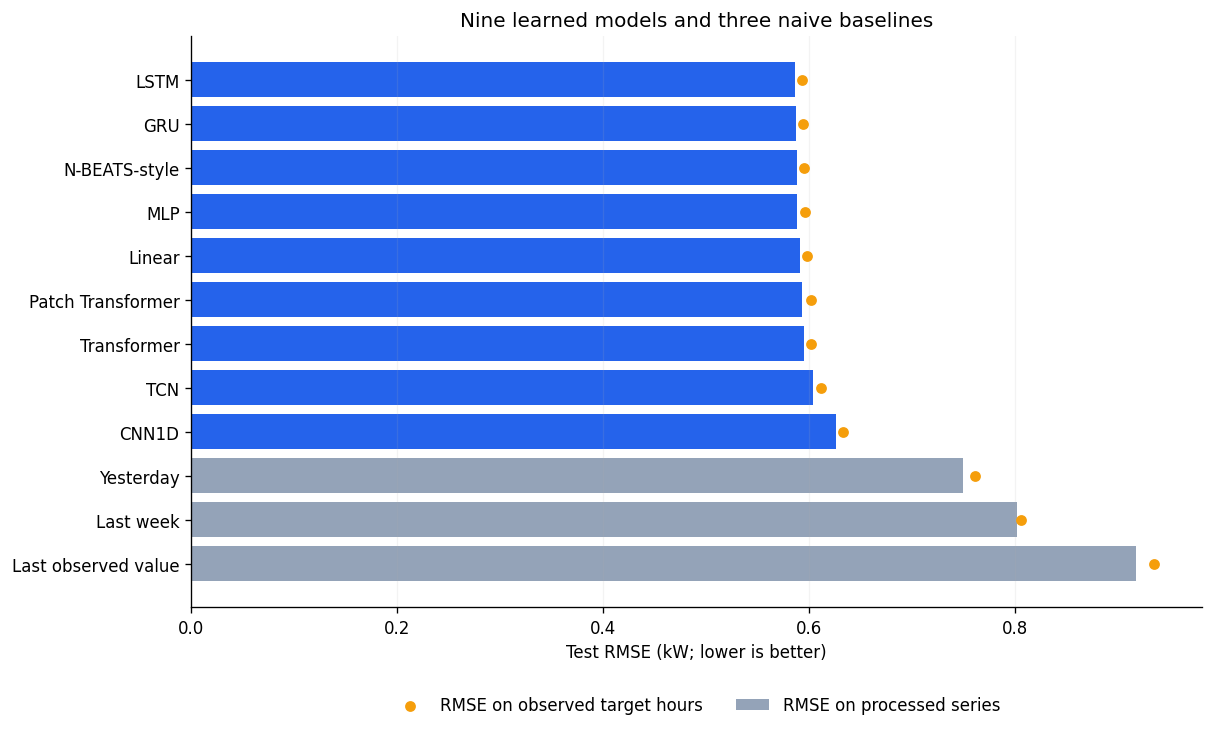

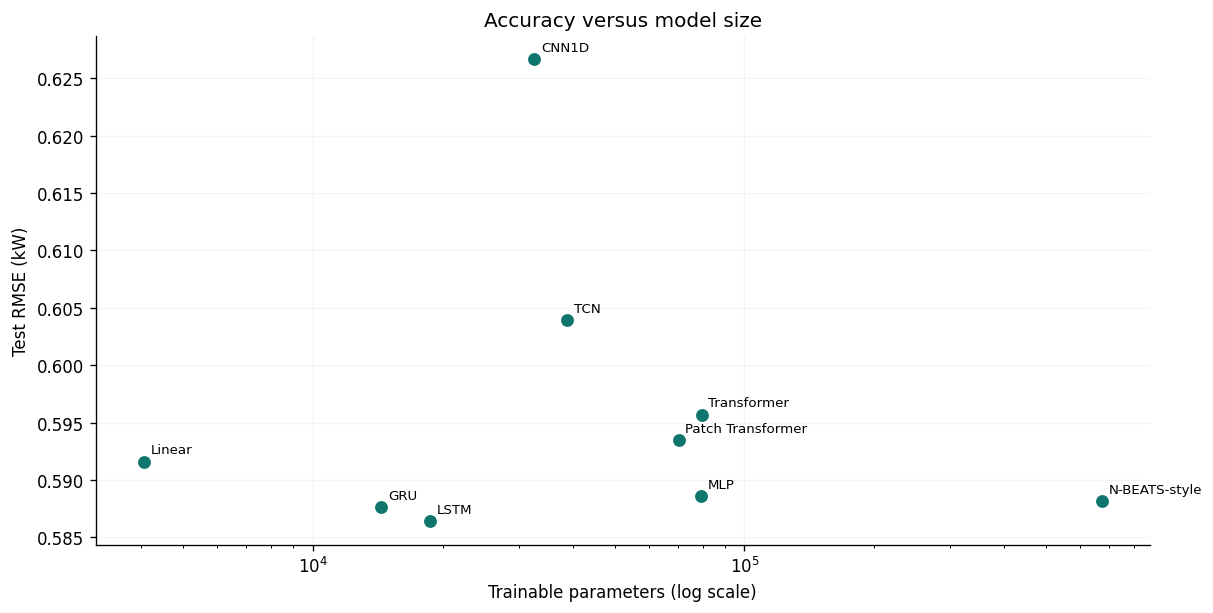

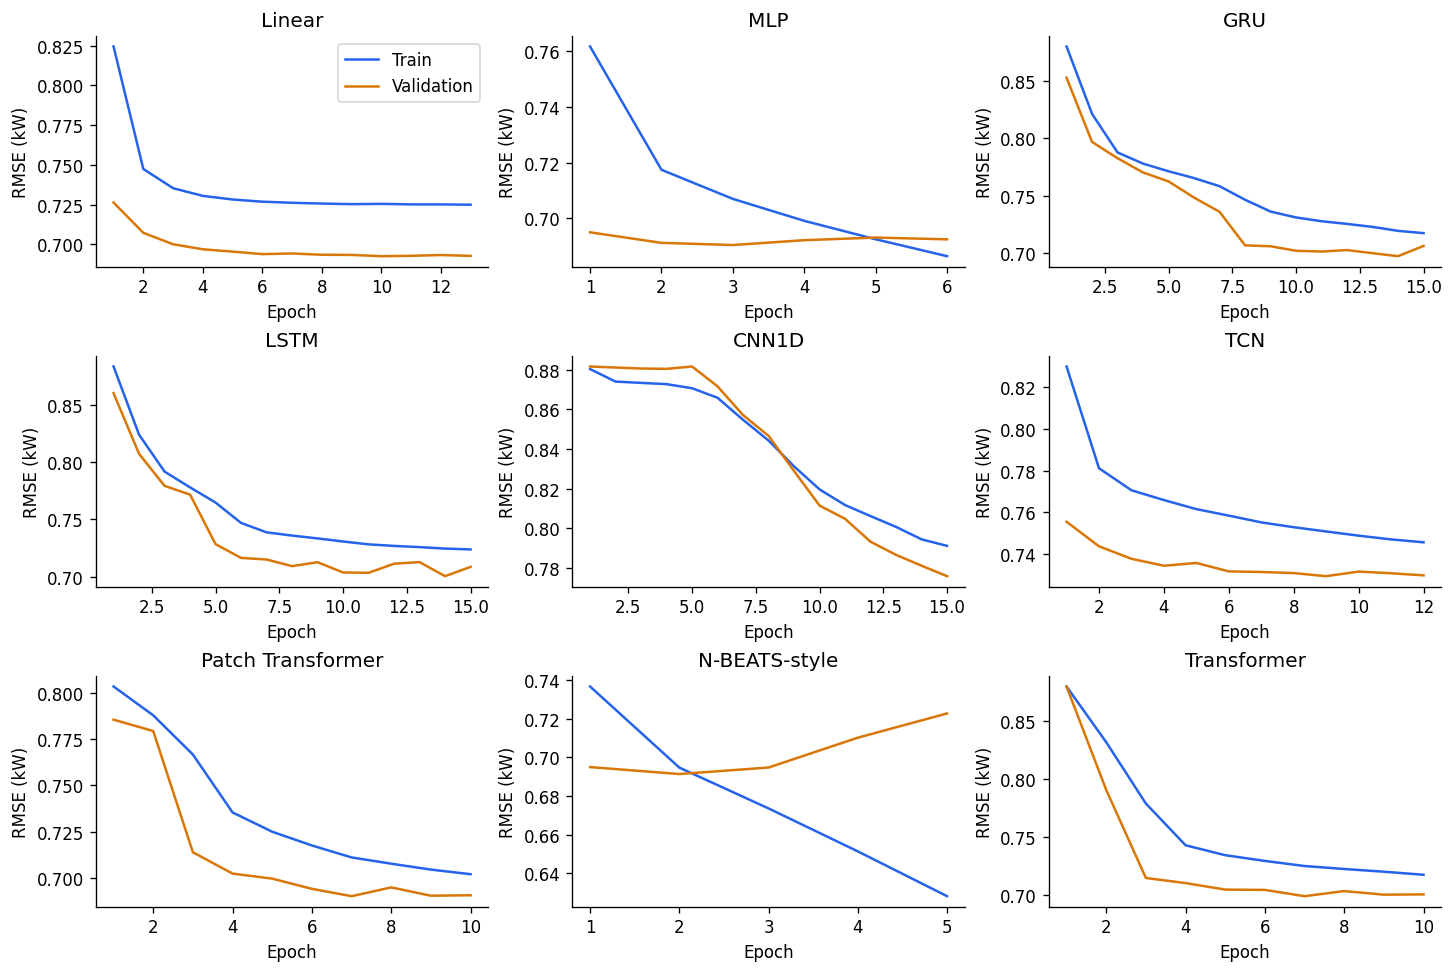

In [12]:
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
chart = results.iloc[::-1]
colors = ["#94a3b8" if kind == "Naive" else "#2563eb" for kind in chart["kind"]]
ax.barh(chart["model"], chart["test_rmse_kw"], color=colors, label="RMSE on processed series")
ax.scatter(chart["observed_rmse_kw"], chart["model"], color="#f59e0b", s=30,
            zorder=3, label="RMSE on observed target hours")
ax.set(xlabel="Test RMSE (kW; lower is better)", title="Nine learned models and three naive baselines")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False)
ax.grid(axis="x", alpha=0.15)
fig.savefig(OUTPUT_DIR / "model_comparison.png", bbox_inches="tight")
plt.show()

learned = results[results["kind"] == "Learned"]
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.scatter(learned["parameters"], learned["test_rmse_kw"], color="#0f766e", s=45)
for _, row in learned.iterrows():
    ax.annotate(row["model"], (row["parameters"], row["test_rmse_kw"]),
                xytext=(4, 5), textcoords="offset points", fontsize=8)
ax.set(xscale="log", xlabel="Trainable parameters (log scale)", ylabel="Test RMSE (kW)",
        title="Accuracy versus model size")
ax.grid(alpha=0.15)
fig.savefig(OUTPUT_DIR / "accuracy_vs_size.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(12, 8), constrained_layout=True)
for ax, name in zip(axes.flat, MODEL_NAMES):
    history = pd.DataFrame(histories[name])
    ax.plot(history["epoch"], history["train_rmse_kw"], label="Train", color="#2563eb")
    ax.plot(history["epoch"], history["validation_rmse_kw"], label="Validation", color="#d97706")
    ax.set(title=name, xlabel="Epoch", ylabel="RMSE (kW)")
axes.flat[0].legend()
fig.savefig(OUTPUT_DIR / "learning_curves.png", bbox_inches="tight")
plt.show()

Best measured learned model in this run: LSTM.
Test RMSE: 0.586379 kW; observed-target-only RMSE: 0.593479 kW.
RMSE reduction versus yesterday: 21.78%.
Linear RMSE gap versus the best model: 0.89%.


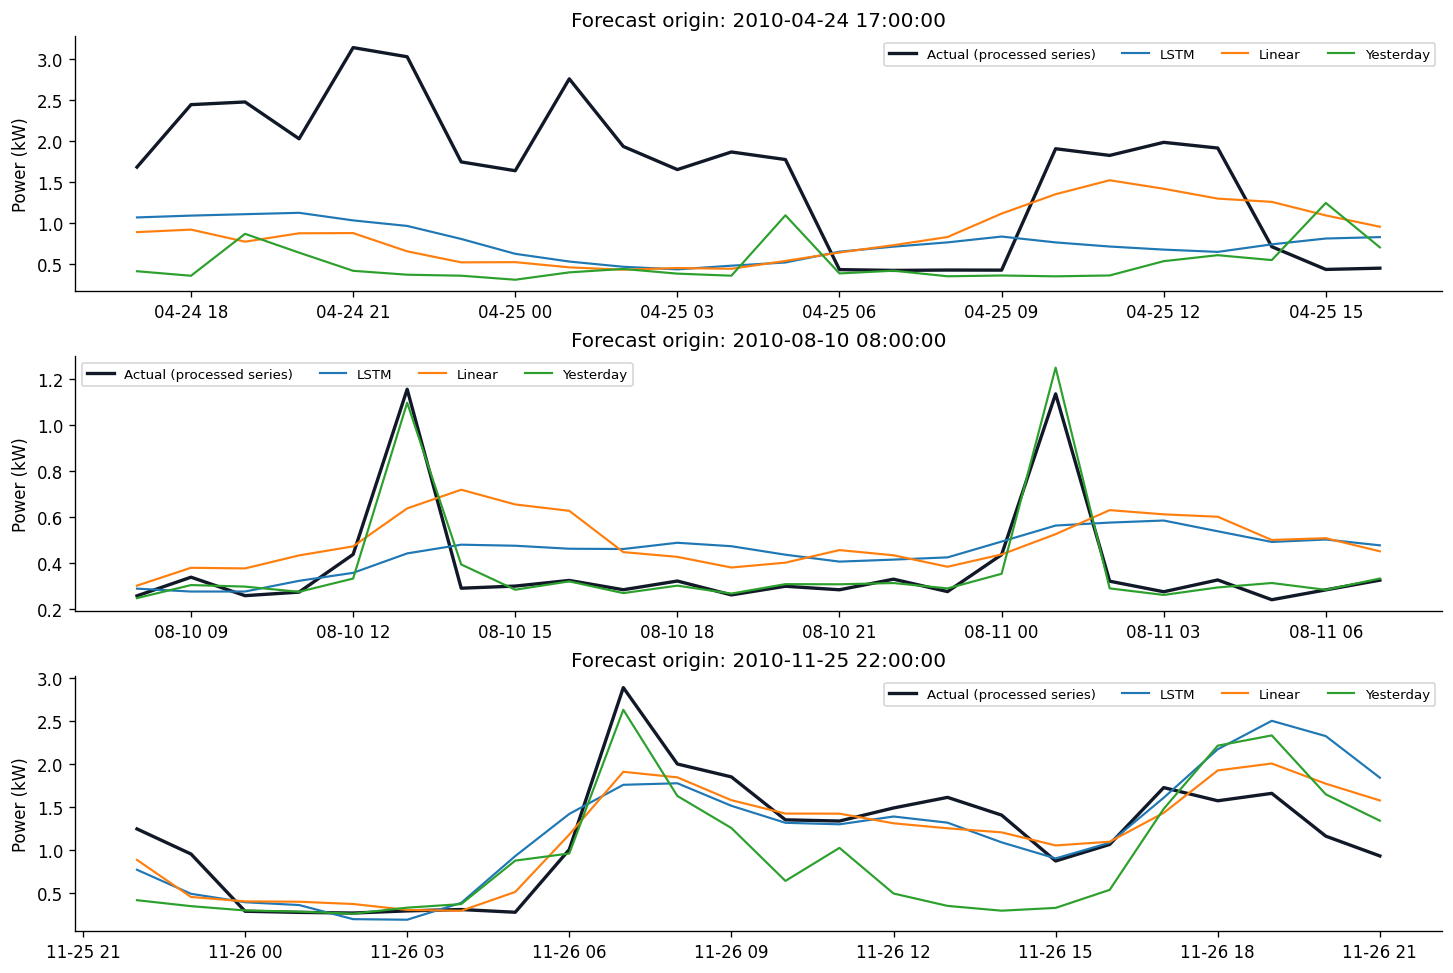

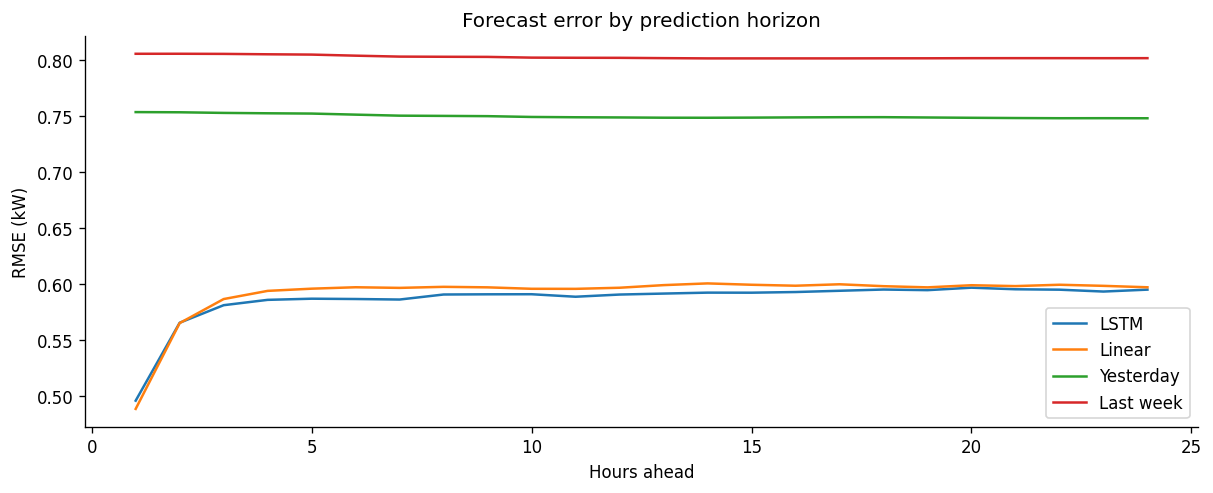

In [13]:
best_name = learned.iloc[0]["model"]
selected_names = [best_name, "Linear", "Yesterday"]
selected_names = list(dict.fromkeys(selected_names))
fig, axes = plt.subplots(3, 1, figsize=(12, 8), constrained_layout=True)
for ax, example in zip(axes, [0, len(test_origins) // 2, len(test_origins) - 1]):
    t = int(test_origins[example])
    hours = hourly.index[t:t+HORIZON]
    ax.plot(hours, y_test_kw[example], color="#111827", lw=2, label="Actual (processed series)")
    for name in selected_names:
        ax.plot(hours, predictions_by_model[name][example], lw=1.3, label=name)
    ax.set(ylabel="Power (kW)", title=f"Forecast origin: {hours[0]}")
    ax.legend(ncol=4, fontsize=8)
fig.savefig(OUTPUT_DIR / "forecast_examples.png", bbox_inches="tight")
plt.show()

horizon_rows = []
for name, prediction in predictions_by_model.items():
    rmse = np.sqrt(np.mean((prediction - y_test_kw)**2, axis=0))
    horizon_rows.extend({"model": name, "horizon_hour": int(h+1), "rmse_kw": float(value)}
                        for h, value in enumerate(rmse))
horizon_results = pd.DataFrame(horizon_rows)
horizon_results.to_csv(OUTPUT_DIR / "rmse_by_horizon.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
for name in [best_name, "Linear", "Yesterday", "Last week"]:
    group = horizon_results[horizon_results["model"] == name]
    ax.plot(group["horizon_hour"], group["rmse_kw"], label=name)
ax.set(xlabel="Hours ahead", ylabel="RMSE (kW)", title="Forecast error by prediction horizon")
ax.legend()
fig.savefig(OUTPUT_DIR / "rmse_by_horizon.png", bbox_inches="tight")
plt.show()

best = learned.iloc[0]
linear = learned[learned["model"] == "Linear"].iloc[0]
yesterday = baselines[baselines["model"] == "Yesterday"].iloc[0]
improvement = 100 * (1 - best["test_rmse_kw"] / yesterday["test_rmse_kw"])
linear_gap = 100 * (linear["test_rmse_kw"] / best["test_rmse_kw"] - 1)
print(f"Best measured learned model in this run: {best_name}.")
print(f"Test RMSE: {best['test_rmse_kw']:.6f} kW; "
      f"observed-target-only RMSE: {best['observed_rmse_kw']:.6f} kW.")
print(f"RMSE reduction versus yesterday: {improvement:.2f}%.")
print(f"Linear RMSE gap versus the best model: {linear_gap:.2f}%.")


## Interpreting the comparison

LSTM, GRU, N-BEATS-style, and MLP produce similar errors in this run. Their
RMSEs range from 0.5864 to 0.5886 kW.
This does not establish a stable ordering from one seed and one test period.

Recurrence is effective here, but a dense model is also competitive. The MLP
maps the fixed 168-hour window directly to 24 outputs. The linear model has
the same input/output contract and is within 0.89% RMSE of LSTM.

Model size alone does not explain the ranking. LSTM uses 18,712 parameters,
GRU 14,424, and the N-BEATS-style model 672,576. The two attention models do
not improve on those compact recurrent models in this configuration.

The convolutional results depend on specific design choices. The TCN's final
state has a 31-hour receptive field, even though the input contains 168 hours.
The CNN uses global average pooling, which removes exact positions. Its
validation error is still decreasing at epoch 15. These results do not isolate
architectural effects from receptive field, pooling, and optimization budget.

## Limits and reproducibility

This experiment covers one household, one chronological split, one seed, and
fixed model settings. It does not include hyperparameter searches, multiple
seeds, rolling forecast periods, or boosted trees. Capacity is not matched.
The primary metric includes forward-filled target hours; the observed-only
score reports sensitivity to that choice.

Checkpoints, predictions, epoch histories, environment versions, and source
metadata are saved under `outputs/` and `data/`. The notebook contains a
compressed data snapshot so it also works without a separate CSV download.

**Data attribution:** Hebrail, G. & Berard, A. (2006). *Individual Household
Electric Power Consumption* [Dataset]. UCI Machine Learning Repository.
https://doi.org/10.24432/C58K54. Licensed CC BY 4.0. Changes: select global
active power, average by hour, flag and forward-fill empty hours, and build
chronological forecast windows.

## Notes on the earlier draft

The source text supplied for this project named the same UCI dataset and listed
34,589 hourly observations. Its validation/test origin counts and three naive
baseline RMSEs match this notebook to four decimals.

It listed 23,853 training origins, 168 fewer than the explicit construction here.
The source text did not include its windowing or training code, so the reason for
that difference is unknown. It also supplied no weights or training logs for its
neural leaderboard. This notebook reports a new execution under the documented
settings; the older neural scores are not used in its result table.